# Predicting Heart Disease: a Decision Tree and a Logistic Regression, Both Written From Scratch

**Course:** Machine Learning (instructor: Alassane Diallo) &nbsp;|&nbsp; **Authors:** Adarsh, Sean and Saathvika
**Dataset:** Heart Failure Prediction Dataset (Kaggle): https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

## 1. Overview

**Question.** Can we predict whether a patient has heart disease from routine clinical measurements, and do models we write ourselves reproduce the results of the scikit-learn versions?

**Task.** Supervised binary classification. Target `HeartDisease` (1 = disease, 0 = no disease).

**Models (both implemented from scratch with NumPy):**
- a **decision tree** (Gini impurity, exhaustive split search),
- a **logistic regression** (cross-entropy loss, batch gradient descent).

Each is compared with the scikit-learn model of the same kind, on identical data and identical folds.

**What we check.** (1) The scratch models should match scikit-learn, with any difference explained. (2) Because a missed patient is worse than a false alarm, we watch **recall** and not only accuracy.

**Evaluation protocol (decided before any model is fitted).**
1. 15 % of the patients are put aside as a **test set** and are used **once**, at the end (Section 6.4).
2. The other 85 % (the *pool*) is used for **5-fold cross-validation** to choose hyperparameters and to compare models.
3. All preprocessing statistics (medians, means, standard deviations) are computed on the training part only, inside every fold.

**How to run.** Put `heart.csv` (downloaded from the Kaggle link above) next to this notebook and run all cells from top to bottom. The random seed is fixed (42). All figures are saved in the `figures/` folder.

## 2. Setup

One colour scheme is used in every figure: **blue = no disease, orange = disease**.

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression as SKLearnLR
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
os.makedirs('figures', exist_ok=True)

# One colour scheme for the whole notebook
C_NO, C_YES = '#4C72B0', '#DD8452'     # blue = no disease, orange = disease
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

def save_fig(name):
    plt.savefig(f'figures/{name}.png', bbox_inches='tight', dpi=150)

print('Setup done.')

Setup done.


## 3. Data and exploratory plots

The exploration below uses all 918 patients and is purely descriptive: nothing from it feeds into a model.

In [2]:
df = pd.read_csv('heart.csv')
print(f'Shape: {df.shape}')
print(f'Missing values (NaN): {int(df.isnull().sum().sum())}')
print('Class counts:', df['HeartDisease'].value_counts().to_dict(), ' -> majority class share = '
      f"{df['HeartDisease'].mean():.1%}")
print(f"Invalid zeros: Cholesterol = {(df['Cholesterol'] == 0).sum()}, RestingBP = {(df['RestingBP'] == 0).sum()}")
zero_chol = df['Cholesterol'] == 0
print(f"Share with disease: patients with Cholesterol = 0: {df.loc[zero_chol, 'HeartDisease'].mean():.3f}, "
      f"all other patients: {df.loc[~zero_chol, 'HeartDisease'].mean():.3f}")
df.head()

Shape: (918, 12)
Missing values (NaN): 0
Class counts: {1: 508, 0: 410}  -> majority class share = 55.3%
Invalid zeros: Cholesterol = 172, RestingBP = 1
Share with disease: patients with Cholesterol = 0: 0.884, all other patients: 0.477


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


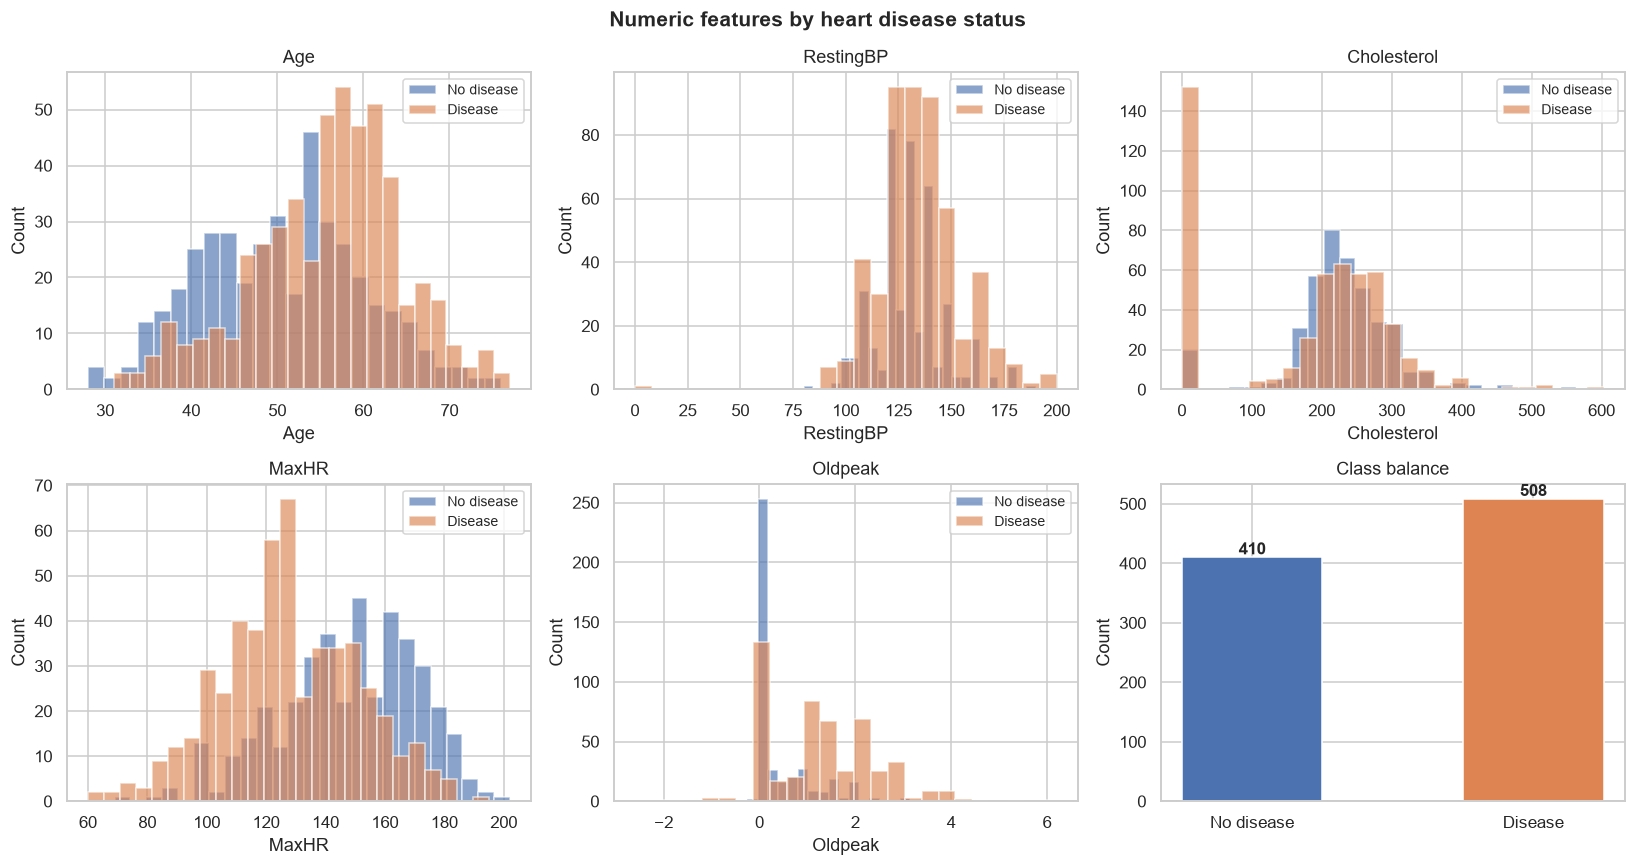

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Numeric features by heart disease status', fontsize=14, fontweight='bold')
for ax, feat in zip(axes.flat, ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']):
    for label, color, name in [(0, C_NO, 'No disease'), (1, C_YES, 'Disease')]:
        ax.hist(df.loc[df['HeartDisease'] == label, feat], bins=25, alpha=0.65, color=color,
                edgecolor='white', label=name)
    ax.set_title(feat); ax.set_xlabel(feat); ax.set_ylabel('Count'); ax.legend(fontsize=9)
ax = axes[1, 2]
counts = df['HeartDisease'].value_counts().sort_index()
bars = ax.bar(['No disease', 'Disease'], counts.values, color=[C_NO, C_YES], edgecolor='white', width=0.5)
for b, c in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, c + 5, str(c), ha='center', fontweight='bold')
ax.set_title('Class balance'); ax.set_ylabel('Count')
plt.tight_layout(); save_fig('fig01_feature_distributions'); plt.show()

**Reading Figure 1.** Patients with disease tend to be older, reach a lower maximum heart rate and have a higher Oldpeak. The Cholesterol panel shows a tall spike at **0**: those are not real measurements but missing values coded as zero (172 patients). We deal with them in Section 4.

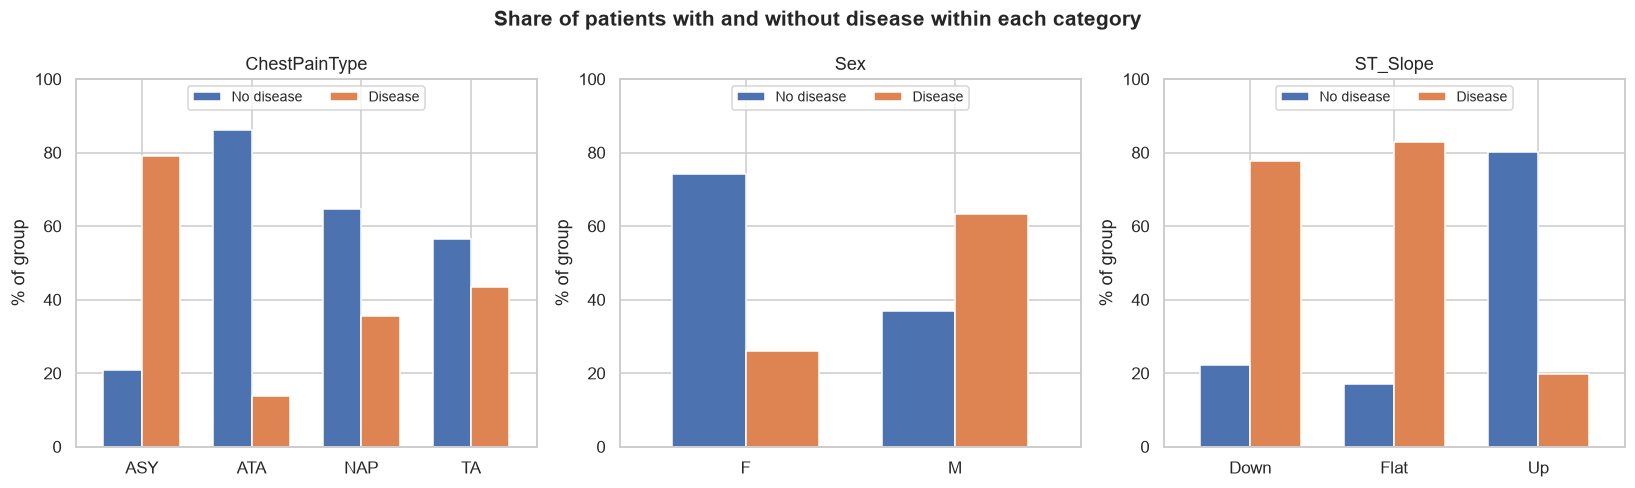

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle('Share of patients with and without disease within each category', fontsize=14, fontweight='bold')
for ax, feat in zip(axes, ['ChestPainType', 'Sex', 'ST_Slope']):
    ct = pd.crosstab(df[feat], df['HeartDisease'], normalize='index') * 100
    ct.plot(kind='bar', ax=ax, color=[C_NO, C_YES], edgecolor='white', width=0.7)
    ax.set_title(feat); ax.set_xlabel(''); ax.set_ylabel('% of group'); ax.tick_params(axis='x', rotation=0)
    ax.set_ylim(0, 100); ax.legend(['No disease', 'Disease'], fontsize=9, loc='upper center', ncol=2)
plt.tight_layout(); save_fig('fig02_categorical_features'); plt.show()

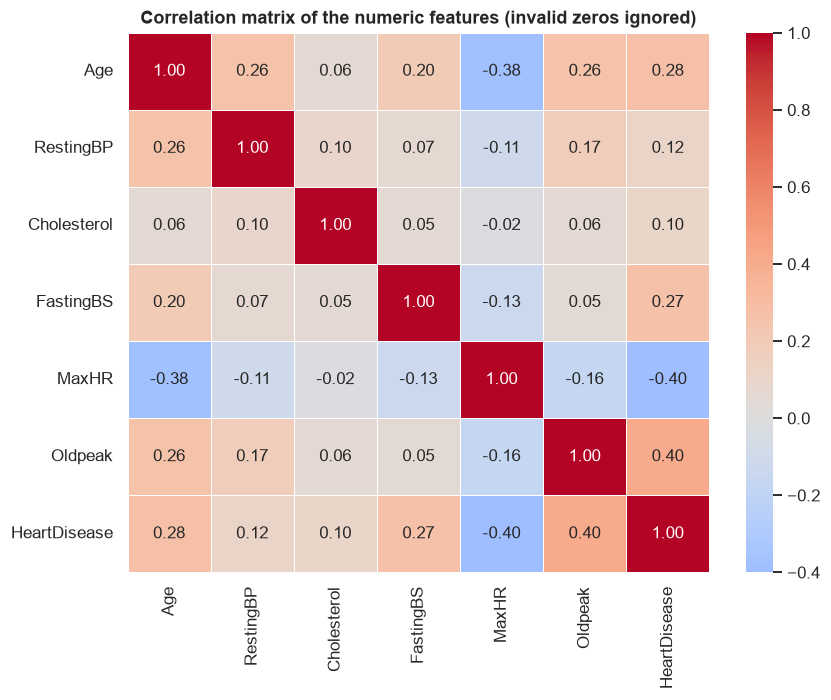

In [5]:
# Correlations: the invalid zeros are treated as missing so that they do not distort the coefficients.
df_corr = df.select_dtypes(include=[np.number]).copy()
df_corr[['Cholesterol', 'RestingBP']] = df_corr[['Cholesterol', 'RestingBP']].replace(0, np.nan)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5, ax=ax)
ax.set_title('Correlation matrix of the numeric features (invalid zeros ignored)', fontweight='bold')
plt.tight_layout(); save_fig('fig03_correlation_heatmap'); plt.show()

## 4. Preprocessing

Three steps, all written so that they use **training data only** whenever they compute a statistic.

**4.1 Encoding.** The five text columns become 0/1 indicator columns (one-hot encoding). Encoding uses no statistics of the data, so it is safe to do before splitting. We keep **two views of the same information**:
- *full one-hot*: one column per level (20 columns). Used by the **tree**.
- *`drop_first`*: for each variable one level, the reference level, is left out (15 columns). Used by the **logistic regression**.

Why two views? The indicator columns of one variable always add up to 1, which is the same as the intercept column. For logistic regression this makes the weights non-unique (we could add a constant to all of them and subtract it from the intercept without changing any prediction), so we remove one column per variable. A tree does not have this problem, and it needs *every* level as its own column, because it can only ask "is this column above a threshold?". Section 7.4 shows what happens if the tree is denied one of them.

**4.2 Invalid zeros.** `Cholesterol` = 0 (172 patients) and `RestingBP` = 0 (1 patient) are impossible values, so we treat them as missing and replace them with the **median of the non-zero training values**. The median is fitted on the training part only. We do not add an extra "was missing" column: it would mostly tell the model which source hospital a patient came from, not anything about the patient (see the limitations in Section 9).

**4.3 Standardisation (logistic regression only).** Each column becomes $(x-\mu)/\sigma$ with $\mu$, $\sigma$ from the training part. Gradient descent is sensitive to feature scale; trees are not, so they use the unscaled values.

In [6]:
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
X_all = pd.get_dummies(df.drop(columns='HeartDisease'), columns=cat_cols, drop_first=False).astype(float)
y_all = df['HeartDisease'].to_numpy()

REFERENCE_LEVELS = ['Sex_F', 'ChestPainType_ASY', 'RestingECG_LVH', 'ExerciseAngina_N', 'ST_Slope_Down']

FULL_COLS = list(X_all.columns)                                          # full one-hot (tree)
DROP_COLS = [c for c in FULL_COLS if c not in REFERENCE_LEVELS]          # drop_first (logistic regression)
print(f'Full one-hot columns: {len(FULL_COLS)}   drop_first columns: {len(DROP_COLS)}')
print('Reference levels left out of the drop_first view:', REFERENCE_LEVELS)

ZERO_COLS = ['Cholesterol', 'RestingBP']

def impute_zeros(train_df, *other_dfs):
    """Replace the invalid zeros by the median of the NON-zero TRAINING values (fitted on train_df only)."""
    medians = {c: train_df.loc[train_df[c] > 0, c].median() for c in ZERO_COLS}
    out = []
    for d in (train_df,) + other_dfs:
        d = d.copy()
        for c, m in medians.items():
            d.loc[d[c] == 0, c] = m
        out.append(d)
    return out, medians

def to_arrays(train_df, other_df, cols, scale=False):
    """Select columns; optionally standardise with the mean/std of the TRAINING part only."""
    A, B = train_df[cols].to_numpy(float), other_df[cols].to_numpy(float)
    if scale:
        mu, sd = A.mean(axis=0), A.std(axis=0)
        sd[sd == 0] = 1.0
        A, B = (A - mu) / sd, (B - mu) / sd
    return A, B

Full one-hot columns: 20   drop_first columns: 15
Reference levels left out of the drop_first view: ['Sex_F', 'ChestPainType_ASY', 'RestingECG_LVH', 'ExerciseAngina_N', 'ST_Slope_Down']


**4.4 Splitting.** 15 % of the patients are set aside as the test set (stratified, so the class ratio is preserved). We do not look at it until Section 6.4.

In [7]:
X_pool, X_test, y_pool, y_test = train_test_split(
    X_all, y_all, test_size=0.15, random_state=RANDOM_SEED, stratify=y_all)
print(f'Pool (cross-validation): {len(y_pool)} patients | Test (kept aside): {len(y_test)} patients')
print(f'Share of disease: pool {y_pool.mean():.3f}, test {y_test.mean():.3f}')

Pool (cross-validation): 780 patients | Test (kept aside): 138 patients
Share of disease: pool 0.554, test 0.551


## 5. Models written from scratch

### 5.1 Decision tree (CART, Gini impurity)

For a node with class proportions $p_k$, the **Gini impurity** is $G = 1-\sum_k p_k^2$. It is 0 for a pure node and 0.5 for an even two-class mix.
A candidate split of a node $t$ ($n$ samples) into a left child ($n_L$) and a right child ($n_R$) is scored by the **Gini gain**
$$\Delta G = G(t) - \tfrac{n_L}{n}\,G(t_L) - \tfrac{n_R}{n}\,G(t_R).$$
**Training** is recursive: at each node, try every feature and every midpoint between consecutive distinct values as a threshold, and keep the split with the largest $\Delta G$. This exhaustive search is the optimisation procedure (no gradient is involved). Recursion stops when the node is pure, has fewer than `min_samples_split` samples, reaches `max_depth`, or no split has positive gain. A split is only allowed if both children keep at least `min_samples_leaf` samples (this prevents leaves with one or two patients).
**Prediction:** a leaf predicts the majority class of its training patients. **Feature importance:** the total sample-weighted Gini decrease contributed by a feature, normalised to sum to 1.

In [8]:
class Node:
    def __init__(self):
        self.feature_index = None   # column used by the split (None for a leaf)
        self.threshold = None       # go left if x[feature] <= threshold
        self.left = None
        self.right = None
        self.value = None           # predicted class (only for a leaf)


class DecisionTreeScratch:
    """Binary decision tree classifier with Gini impurity.

    max_depth         : maximum depth (None = unlimited)
    min_samples_split : a node with fewer samples is not split
    min_samples_leaf  : every child of a split must keep at least this many samples
    """

    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None
        self.feature_importances_ = None

    def _gini(self, y):
        n = len(y)
        if n == 0:
            return 0.0
        p = np.bincount(y) / n
        return 1.0 - np.sum(p ** 2)

    def _best_split(self, X, y):
        """Search every feature and every midpoint threshold; return the split with the largest Gini gain."""
        n, n_features = X.shape
        parent_gini = self._gini(y)
        best_gain, best_feature, best_threshold = -1.0, None, None
        for j in range(n_features):
            col = X[:, j]
            values = np.unique(col)
            for threshold in (values[:-1] + values[1:]) / 2.0:
                left = col <= threshold
                n_left, n_right = left.sum(), n - left.sum()
                if n_left < self.min_samples_leaf or n_right < self.min_samples_leaf:
                    continue
                gain = parent_gini - (n_left / n) * self._gini(y[left]) - (n_right / n) * self._gini(y[~left])
                if gain > best_gain:
                    best_gain, best_feature, best_threshold = gain, j, threshold
        return best_feature, best_threshold, best_gain

    def _build(self, X, y, depth):
        node = Node()
        pure = self._gini(y) == 0.0
        too_small = len(y) < self.min_samples_split
        too_deep = self.max_depth is not None and depth >= self.max_depth
        if pure or too_small or too_deep:
            node.value = int(np.bincount(y).argmax())
            return node
        j, threshold, gain = self._best_split(X, y)
        if j is None or gain <= 0:
            node.value = int(np.bincount(y).argmax())
            return node
        node.feature_index, node.threshold = j, threshold
        self._importance[j] += len(y) * gain
        left = X[:, j] <= threshold
        node.left = self._build(X[left], y[left], depth + 1)
        node.right = self._build(X[~left], y[~left], depth + 1)
        return node

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
        self._importance = np.zeros(X.shape[1])
        self.root = self._build(X, y, depth=0)
        total = self._importance.sum()
        self.feature_importances_ = self._importance / total if total > 0 else self._importance
        return self

    def _predict_one(self, x, node):
        while node.value is None:
            node = node.left if x[node.feature_index] <= node.threshold else node.right
        return node.value

    def predict(self, X):
        return np.array([self._predict_one(x, self.root) for x in np.asarray(X, dtype=float)])

    def get_depth(self, node='root'):
        node = self.root if node == 'root' else node
        return 0 if node.value is not None else 1 + max(self.get_depth(node.left), self.get_depth(node.right))

    def get_n_leaves(self, node='root'):
        node = self.root if node == 'root' else node
        return 1 if node.value is not None else self.get_n_leaves(node.left) + self.get_n_leaves(node.right)

print('DecisionTreeScratch defined.')

DecisionTreeScratch defined.


### 5.2 Logistic regression (batch gradient descent)

The probability of disease is $\hat p(x)=\sigma(z)$ with $z=w^\top x+b$ and $\sigma(z)=1/(1+e^{-z})$. We predict class 1 when $\hat p\ge 0.5$, i.e. when $z\ge 0$: a linear decision boundary.

**Objective** (negative log-likelihood = binary cross-entropy, no penalty term):
$$L(w,b) = -\frac1n\sum_i\big[y_i\log\hat p_i + (1-y_i)\log(1-\hat p_i)\big].$$
**Gradient.** Since $\sigma'(z)=\sigma(z)(1-\sigma(z))$, the chain rule collapses to "prediction error times input":
$$\frac{\partial L}{\partial w}=\frac1n X^\top(\hat p-y),\qquad \frac{\partial L}{\partial b}=\frac1n\sum_i(\hat p_i-y_i).$$
**Training.** Start from $w=0,\ b=0$ and repeat $w\leftarrow w-\alpha\,\partial L/\partial w$, $b\leftarrow b-\alpha\,\partial L/\partial b$ for a fixed number of iterations (2000), using all training patients at each step. The loss is convex, so there is no bad local minimum. For numerical safety, $z$ is clipped to $[-500,500]$ before exponentiating and $\hat p$ to $[10^{-15},1-10^{-15}]$ before taking logarithms.

In [9]:
class LogisticRegressionScratch:
    """Binary logistic regression trained by batch gradient descent (no regularisation).

    lr           : learning rate alpha
    n_iterations : number of gradient descent steps
    """

    def __init__(self, lr=0.1, n_iterations=2000):
        self.lr = lr
        self.n_iterations = n_iterations
        self.weights, self.bias = None, None
        self.loss_history = []                    # training cross-entropy after every step

    def _sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def _cross_entropy(self, y, p_hat):
        p_hat = np.clip(p_hat, 1e-15, 1 - 1e-15)
        return -np.mean(y * np.log(p_hat) + (1 - y) * np.log(1 - p_hat))

    def objective(self, X, y, w, b):
        """Loss L(w, b) for given parameters."""
        return self._cross_entropy(y, self._sigmoid(X @ w + b))

    def gradients(self, X, y, w, b):
        """Analytical gradient (dL/dw, dL/db)."""
        error = self._sigmoid(X @ w + b) - y
        return X.T @ error / X.shape[0], error.mean()

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        self.weights, self.bias = np.zeros(X.shape[1]), 0.0
        self.loss_history = []
        for _ in range(self.n_iterations):
            self.loss_history.append(self.objective(X, y, self.weights, self.bias))
            dw, db = self.gradients(X, y, self.weights, self.bias)
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
        return self

    def predict_proba(self, X):
        return self._sigmoid(np.asarray(X, dtype=float) @ self.weights + self.bias)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def cross_entropy_loss(self, X, y):
        return self._cross_entropy(np.asarray(y, dtype=float), self.predict_proba(X))

print('LogisticRegressionScratch defined.')

LogisticRegressionScratch defined.


### 5.3 Numerical check of the gradient

Before training anything we compare the hand-derived gradient with a central finite difference, $\big(L(\theta+h e_k)-L(\theta-h e_k)\big)/2h$ with $h=10^{-5}$, for every weight and the bias, at random non-zero parameters. (This check uses the training pool only to have realistic inputs; no model is evaluated here.)

In [10]:
(pool_demo,), _ = impute_zeros(X_pool)
Xg, _ = to_arrays(pool_demo, pool_demo, DROP_COLS, scale=True)
yg = y_pool.astype(float)

model = LogisticRegressionScratch()
rng = np.random.default_rng(RANDOM_SEED)
w0, b0 = rng.normal(scale=0.3, size=Xg.shape[1]), 0.1

dw_a, db_a = model.gradients(Xg, yg, w0, b0)
h = 1e-5
dw_n = np.array([(model.objective(Xg, yg, w0 + h * e, b0) - model.objective(Xg, yg, w0 - h * e, b0)) / (2 * h)
                 for e in np.eye(len(w0))])
db_n = (model.objective(Xg, yg, w0, b0 + h) - model.objective(Xg, yg, w0, b0 - h)) / (2 * h)

analytic, numeric = np.append(dw_a, db_a), np.append(dw_n, db_n)
max_abs = np.abs(analytic - numeric).max()
print(f'{len(analytic)} parameters checked: largest |analytical - numerical| = {max_abs:.1e}')
assert max_abs < 1e-7, 'gradient check failed'
print('Gradient check passed.')

16 parameters checked: largest |analytical - numerical| = 5.0e-12
Gradient check passed.


## 6. Experiments

### 6.1 Cross-validation set-up

The pool is split into 5 stratified folds. Each fold in turn is the **validation part** (156 patients) while the other four form the **training part** (624 patients). In every fold the zeros are imputed and the columns standardised using that fold's training part only.

We tune with the **mean validation accuracy** (tree) or **mean validation cross-entropy** (logistic regression). Cross-entropy uses the predicted probabilities, so it is less noisy than accuracy on 156 patients. Ties go to the simpler model.

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
folds = []
for k, (tr, va) in enumerate(skf.split(X_pool, y_pool), start=1):
    (tr_df, va_df), _ = impute_zeros(X_pool.iloc[tr], X_pool.iloc[va])      # medians from the training part only
    folds.append({'tr': tr_df, 'va': va_df, 'y_tr': y_pool[tr], 'y_va': y_pool[va]})
print('Fold sizes (train / validation):', [(len(f['y_tr']), len(f['y_va'])) for f in folds][:1], 'x 5 folds')

Fold sizes (train / validation): [(624, 156)] x 5 folds


### 6.2 Tuning

#### Decision tree: `max_depth` and `min_samples_leaf`
Grid: `max_depth` 1 to 10 and `min_samples_leaf` in {1, 5, 10, 20}, on the full one-hot columns. We choose the setting with the highest mean validation accuracy; ties go to the tree with fewer leaves.

#### Logistic regression: learning rate $\alpha$
Grid: $\alpha\in\{0.001, 0.01, 0.05, 0.1, 0.3, 0.5\}$, 2000 iterations each, on the `drop_first` columns. We choose the $\alpha$ with the lowest mean validation cross-entropy.

In [12]:
TREE_GRID = [(d, leaf) for d in range(1, 11) for leaf in (1, 5, 10, 20)]
ALPHAS = [0.001, 0.01, 0.05, 0.1, 0.3, 0.5]
N_ITER = 2000

def fold_arrays(cols, scale=False):
    return [to_arrays(f['tr'], f['va'], cols, scale) for f in folds]

def tune_tree(cols):
    """Mean 5-fold train/validation accuracy for every (max_depth, min_samples_leaf); returns table and best row."""
    arrays, rows = fold_arrays(cols), []
    for depth, leaf in TREE_GRID:
        tr_acc, va_acc, n_leaves = [], [], []
        for (Xtr, Xva), f in zip(arrays, folds):
            t = DecisionTreeScratch(max_depth=depth, min_samples_leaf=leaf).fit(Xtr, f['y_tr'])
            tr_acc.append(accuracy_score(f['y_tr'], t.predict(Xtr)))
            va_acc.append(accuracy_score(f['y_va'], t.predict(Xva)))
            n_leaves.append(t.get_n_leaves())
        rows.append({'max_depth': depth, 'min_samples_leaf': leaf, 'train_acc': np.mean(tr_acc),
                     'val_acc': np.mean(va_acc), 'val_std': np.std(va_acc, ddof=1), 'leaves': np.mean(n_leaves)})
    grid = pd.DataFrame(rows)
    ranked = grid.assign(_a=grid['val_acc'].round(10)).sort_values(
        ['_a', 'leaves', 'max_depth'], ascending=[False, True, True]).drop(columns='_a').reset_index(drop=True)
    return grid, ranked

def tune_lr(cols):
    """Mean 5-fold validation cross-entropy and accuracy for every learning rate; returns table and best row."""
    arrays, rows = fold_arrays(cols, scale=True), []
    for a in ALPHAS:
        ce, acc = [], []
        for (Xtr, Xva), f in zip(arrays, folds):
            m = LogisticRegressionScratch(lr=a, n_iterations=N_ITER).fit(Xtr, f['y_tr'])
            ce.append(m.cross_entropy_loss(Xva, f['y_va']))
            acc.append(accuracy_score(f['y_va'], m.predict(Xva)))
        rows.append({'alpha': a, 'val_cross_entropy': np.mean(ce), 'val_acc': np.mean(acc)})
    table = pd.DataFrame(rows)
    return table, table.loc[table['val_cross_entropy'].idxmin()]

# ---- Decision tree on the full one-hot columns ----
tree_grid, ranked = tune_tree(FULL_COLS)
best_tree = ranked.iloc[0]
TREE_COLS = FULL_COLS
print(f'Decision tree, full one-hot: top 3 of {len(ranked)} settings')
display(ranked.head(3).round(3))
print(f"-> Selected: max_depth = {int(best_tree['max_depth'])}, "
      f"min_samples_leaf = {int(best_tree['min_samples_leaf'])} (mean validation accuracy {best_tree['val_acc']:.3f})")

Decision tree, full one-hot: top 3 of 40 settings


,max_depth,min_samples_leaf,train_acc,val_acc,val_std,leaves
0,4,20,0.866,0.842,0.028,13.4
1,5,20,0.866,0.842,0.028,14.6
2,6,20,0.866,0.842,0.028,16.2


-> Selected: max_depth = 4, min_samples_leaf = 20 (mean validation accuracy 0.842)


In [13]:
# ---- The same tree algorithm on the drop_first columns (to show the effect of the encoding, Section 7.4) ----
DROP_TREE_COLS = DROP_COLS
drop_grid, drop_ranked = tune_tree(DROP_TREE_COLS)
best_drop = drop_ranked.iloc[0]
print('Decision tree on drop_first columns: top 3 settings')
display(drop_ranked.head(3).round(3))
print(f"-> Selected: max_depth = {int(best_drop['max_depth'])}, min_samples_leaf = {int(best_drop['min_samples_leaf'])} "
      f"(mean validation accuracy {best_drop['val_acc']:.3f})")

Decision tree on drop_first columns: top 3 settings


,max_depth,min_samples_leaf,train_acc,val_acc,val_std,leaves
0,3,1,0.858,0.833,0.019,8.0
1,3,5,0.857,0.833,0.016,8.0
2,3,10,0.858,0.833,0.016,8.0


-> Selected: max_depth = 3, min_samples_leaf = 1 (mean validation accuracy 0.833)


In [14]:
# ---- Logistic regression on the drop_first columns ----
lr_table, lr_best = tune_lr(DROP_COLS)
display(lr_table.round(4))
LR_COLS = DROP_COLS
best_alpha = float(lr_best['alpha'])
print(f"-> Selected alpha = {best_alpha} (mean validation cross-entropy {lr_best['val_cross_entropy']:.4f}, "
      f"validation accuracy {lr_best['val_acc']:.3f})")

,alpha,val_cross_entropy,val_acc
0,0.001,0.4118,0.8526
1,0.010,0.3546,0.8526
2,0.050,0.3616,0.8474
3,0.100,0.3622,0.8474
4,0.300,0.3623,0.8474
5,0.500,0.3623,0.8474


-> Selected alpha = 0.01 (mean validation cross-entropy 0.3546, validation accuracy 0.853)


#### Figure 4: accuracy against tree depth
Mean training and validation accuracy over the 5 folds, for the full one-hot columns. **Left:** no limit on the leaf size (`min_samples_leaf = 1`): training accuracy keeps rising towards 1 while validation accuracy falls. The tree memorises the training patients (overfitting). **Right:** the selected `min_samples_leaf`: no leaf may hold fewer than that many patients, so the tree stops growing and both curves flatten, with a much smaller gap between them.

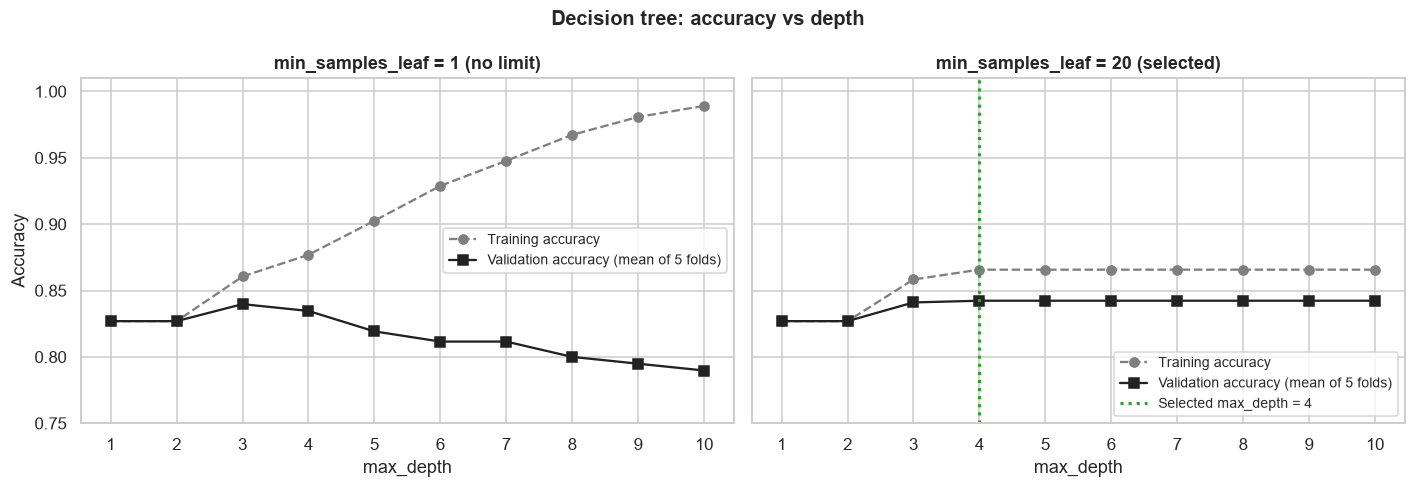

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
sel_leaf = int(best_tree['min_samples_leaf'])
for ax, leaf, ttl in [(axes[0], 1, 'min_samples_leaf = 1 (no limit)'), (axes[1], sel_leaf, f'min_samples_leaf = {sel_leaf} (selected)')]:
    g = tree_grid[tree_grid['min_samples_leaf'] == leaf].sort_values('max_depth')
    ax.plot(g['max_depth'], g['train_acc'], 'o--', color='#7F7F7F', label='Training accuracy')
    ax.plot(g['max_depth'], g['val_acc'], 's-', color='#222222', label='Validation accuracy (mean of 5 folds)')
    if leaf == sel_leaf:
        ax.axvline(int(best_tree['max_depth']), color='#2ca02c', linestyle=':', linewidth=2,
                   label=f"Selected max_depth = {int(best_tree['max_depth'])}")
    ax.set_xlabel('max_depth'); ax.set_xticks(range(1, 11)); ax.set_title(ttl, fontweight='bold'); ax.legend(loc='center right' if leaf == 1 else 'lower right', fontsize=9)
axes[0].set_ylabel('Accuracy'); axes[0].set_ylim(0.75, 1.01)
fig.suptitle('Decision tree: accuracy vs depth', fontsize=13, fontweight='bold')
plt.tight_layout(); save_fig('fig04_tree_depth_cv'); plt.show()

#### Figure 5: learning curves for different learning rates
Training loss against iteration, one line per $\alpha$ (the horizontal axis is logarithmic so that both fast and slow runs are visible). The dashed line is the loss reached by scikit-learn's solver, i.e. the minimum we are trying to reach. A very small $\alpha$ is still far from it after 2000 steps; larger values reach it within a few hundred steps and then all look the same. (Illustration on the training pool; nothing is evaluated here.)

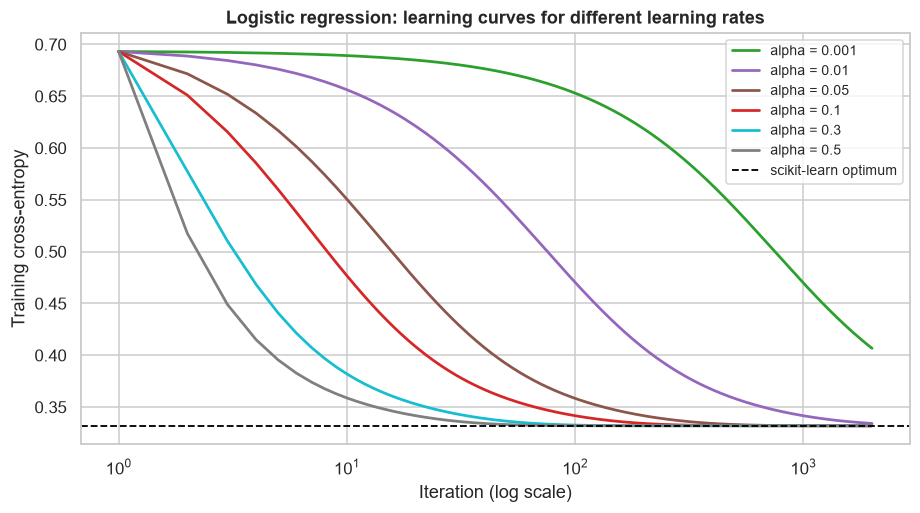

{0.001: 0.4067, 0.01: 0.3342, 0.05: 0.332, 0.1: 0.332, 0.3: 0.332, 0.5: 0.332}
scikit-learn optimum: 0.332


In [16]:
Xp, _ = to_arrays(pool_demo, pool_demo, DROP_COLS, scale=True)
line_colors = ['#2ca02c', '#9467bd', '#8c564b', '#d62728', '#17becf', '#7F7F7F']
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for a, c in zip(ALPHAS, line_colors):
    m = LogisticRegressionScratch(lr=a, n_iterations=N_ITER).fit(Xp, y_pool)
    ax.plot(np.arange(1, N_ITER + 1), m.loss_history, color=c, linewidth=1.8, label=f'alpha = {a}')
ref = SKLearnLR(C=np.inf, max_iter=10000, tol=1e-10).fit(Xp, y_pool)
ref_loss = LogisticRegressionScratch().objective(Xp, y_pool.astype(float), ref.coef_[0], ref.intercept_[0])
ax.axhline(ref_loss, color='black', linestyle='--', linewidth=1.2, label='scikit-learn optimum')
ax.set_xscale('log'); ax.set_xlabel('Iteration (log scale)'); ax.set_ylabel('Training cross-entropy')
ax.set_title('Logistic regression: learning curves for different learning rates', fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout(); save_fig('fig05_lr_learning_curves'); plt.show()
print({a: round(float(LogisticRegressionScratch(lr=a, n_iterations=N_ITER).fit(Xp, y_pool).loss_history[-1]), 4) for a in ALPHAS})
print('scikit-learn optimum:', round(float(ref_loss), 4))

### 6.3 Cross-validated comparison of all models

Every model is evaluated on the **same five folds**, with the hyperparameters chosen above. For each setting we fit the scratch model and the scikit-learn model with identical hyperparameters. Scikit-learn's logistic regression is run **without a penalty** (`C=np.inf`) and a tight tolerance, so it minimises exactly the same objective as ours.

In [17]:
def metrics(y_true, y_pred, proba=None):
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred, zero_division=0),
            'Recall': recall_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred),
            'ROC-AUC': roc_auc_score(y_true, proba) if proba is not None else np.nan}

def make_tree(impl, depth, leaf):
    if impl == 'scratch':
        return DecisionTreeScratch(max_depth=depth, min_samples_leaf=leaf)
    return DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, criterion='gini', random_state=RANDOM_SEED)

def make_lr(impl, alpha):
    if impl == 'scratch':
        return LogisticRegressionScratch(lr=alpha, n_iterations=N_ITER)
    return SKLearnLR(C=np.inf, max_iter=10000, tol=1e-10)

# Each entry: label, kind, columns, hyperparameters
CV_MODELS = [
    ('Tree, full one-hot',  'tree', FULL_COLS, (int(best_tree['max_depth']), int(best_tree['min_samples_leaf']))),
    ('Tree, drop_first',    'tree', DROP_COLS, (int(best_drop['max_depth']), int(best_drop['min_samples_leaf']))),
    ('Logistic regression', 'lr',   DROP_COLS, best_alpha),
]
FINAL_TREE, FINAL_DROP, FINAL_LR = 'Tree, full one-hot', 'Tree, drop_first', 'Logistic regression'

records, agreement = [], {}

for label, kind, cols, hp in CV_MODELS:
    arrays = fold_arrays(cols, scale=(kind == 'lr'))
    agree = []
    for k, ((Xtr, Xva), f) in enumerate(zip(arrays, folds), start=1):
        preds = {}
        for impl in ('scratch', 'sklearn'):
            if kind == 'tree':
                m = make_tree(impl, *hp).fit(Xtr, f['y_tr'])
                preds[impl], proba = m.predict(Xva), None
            else:
                m = make_lr(impl, hp).fit(Xtr, f['y_tr'])
                proba = m.predict_proba(Xva) if impl == 'scratch' else m.predict_proba(Xva)[:, 1]
                preds[impl] = m.predict(Xva)
            records.append({'model': label, 'impl': impl, 'fold': k, **metrics(f['y_va'], preds[impl], proba)})
        agree.append(float((preds['scratch'] == preds['sklearn']).mean()))
    agreement[label] = float(np.mean(agree))
cv = pd.DataFrame(records)
print('Cross-validation finished:', len(cv), 'fold results.')

Cross-validation finished: 30 fold results.


**Table 1: accuracy in each of the five validation folds** (scratch models, with the settings selected above).

In [18]:
acc = cv[cv['impl'] == 'scratch'].pivot(index='fold', columns='model', values='Accuracy')
t1 = acc[[FINAL_TREE, FINAL_DROP, FINAL_LR]].copy()
t1.columns = ['Tree (full one-hot)', 'Tree (drop_first)', 'Logistic regression']
t1.index = [f'Fold {k}' for k in t1.index]
t1.loc['Mean'] = t1.mean()
t1.loc['Std'] = t1.iloc[:5].std(ddof=1)
display(t1.round(3))

lr_vs_tree = t1['Logistic regression'].iloc[:5] - t1['Tree (full one-hot)'].iloc[:5]
tree_vs_drop = t1['Tree (full one-hot)'].iloc[:5] - t1['Tree (drop_first)'].iloc[:5]
print(f'Logistic regression beats the full one-hot tree in {(lr_vs_tree > 0).sum()} of 5 folds '
      f'(ties {(lr_vs_tree == 0).sum()}, losses {(lr_vs_tree < 0).sum()}); mean difference {lr_vs_tree.mean():+.3f}')
print(f'Full one-hot tree beats the drop_first tree in {(tree_vs_drop > 0).sum()} of 5 folds '
      f'(ties {(tree_vs_drop == 0).sum()}, losses {(tree_vs_drop < 0).sum()}); mean difference {tree_vs_drop.mean():+.3f}')

,Tree (full one-hot),Tree (drop_first),Logistic regression
Fold 1,0.833,0.853,0.859
Fold 2,0.801,0.808,0.801
Fold 3,0.878,0.840,0.897
Fold 4,0.846,0.821,0.853
Fold 5,0.853,0.846,0.853
Mean,0.842,0.833,0.853
Std,0.028,0.019,0.034


Logistic regression beats the full one-hot tree in 3 of 5 folds (ties 2, losses 0); mean difference +0.010
Full one-hot tree beats the drop_first tree in 3 of 5 folds (ties 0, losses 2); mean difference +0.009


**Table 2: all models, mean ± standard deviation over the 5 validation folds.** The last column is the share of validation patients on which the scratch and scikit-learn models give the same prediction. ROC-AUC is only computed for logistic regression (our tree outputs classes, not probabilities).

In [19]:
order = [m[0] for m in CV_MODELS]
rows = []
for label in order:
    for impl in ('scratch', 'sklearn'):
        sub = cv[(cv['model'] == label) & (cv['impl'] == impl)]
        row = {'Model': label, 'Implementation': impl}
        for mname in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']:
            vals = sub[mname]
            row[mname] = '-' if vals.isna().all() else f'{vals.mean():.3f} ± {vals.std(ddof=1):.3f}'
        row['Agreement scratch/sklearn'] = f'{agreement[label]:.3f}' if impl == 'scratch' else ''
        rows.append(row)
t2 = pd.DataFrame(rows).set_index(['Model', 'Implementation'])
display(t2)

Accuracy      Precision  \
Model               Implementation                                 
Tree, full one-hot  scratch         0.842 ± 0.028  0.846 ± 0.020   
                    sklearn         0.842 ± 0.028  0.846 ± 0.020   
Tree, drop_first    scratch         0.833 ± 0.019  0.832 ± 0.027   
                    sklearn         0.833 ± 0.019  0.832 ± 0.027   
Logistic regression scratch         0.853 ± 0.034  0.858 ± 0.027   
                    sklearn         0.847 ± 0.048  0.857 ± 0.040   

                                           Recall             F1  \
Model               Implementation                                 
Tree, full one-hot  scratch         0.875 ± 0.033  0.860 ± 0.025   
                    sklearn         0.875 ± 0.033  0.860 ± 0.025   
Tree, drop_first    scratch         0.877 ± 0.018  0.854 ± 0.014   
                    sklearn         0.877 ± 0.018  0.854 ± 0.014   
Logistic regression scratch         0.880 ± 0.043  0.868 ± 0.031   
                    sklearn         0.871 ± 0.053  0.863 ± 0.042   

                                          ROC-AUC Agreement scratch/sklearn  
Model               Implementation                                           
Tree, full one-hot  scratch                     -                     1.000  
                    sklearn                     -                            
Tree, drop_first    scratch                     -                     1.000  
                    sklearn                     -                            
Logistic regression scratch         0.920 ± 0.036                     0.987  
                    sklearn         0.917 ± 0.038

**Reading Tables 1 and 2.**
- **Which model is best?** Logistic regression has the highest mean accuracy (0.853 ± 0.034), followed by the tree on the full one-hot columns (0.842 ± 0.028) and the tree on the `drop_first` columns (0.833 ± 0.019). The differences are small. Logistic regression is ahead of the full one-hot tree by 1.0 point on average (better in 3 of 5 folds, tied in 2, never worse), while each model's accuracy varies by about 3 points from fold to fold. Cross-validation therefore gives logistic regression a slight edge but cannot separate the two models with confidence. Recall is about the same (0.880 against 0.875); precision is 0.858 against 0.846.
- **Scratch against scikit-learn.** The two trees make identical predictions. For logistic regression the scratch model scores 0.6 points higher than scikit-learn (0.853 against 0.847), well within one standard deviation, and the predictions agree on 98.7 % of the validation patients. One possible explanation, which we did not test, is that our gradient descent stops after a fixed 2000 steps, slightly before the exact minimum.
- **Encoding.** The full one-hot tree is better than the `drop_first` tree in 3 of 5 folds (mean +0.9 points): a small effect (Section 7.4).
- **Tree settings.** The selected tree has `max_depth = 4` and `min_samples_leaf = 20`: no leaf holds fewer than 20 training patients, which avoids leaves built on one or two patients.
- **Learning rate.** $\alpha = 0.01$ has the lowest validation cross-entropy (0.3546). Rates from 0.05 upwards reach the same minimum as scikit-learn on the training data (Figure 5) but give a slightly higher validation loss (0.3616 to 0.3623).

### 6.4 Final evaluation on the held-out test set (used once)

Cross-validation has already settled every choice: the two algorithms, their hyperparameters and their input columns. The test set is **not** used to choose between models or settings; it only gives one unbiased estimate of how the final tree and the final logistic regression, and their scikit-learn counterparts, perform on new patients. Each is refitted on the **whole pool** (780 patients); the imputation medians and the standardisation statistics now come from the pool. The 138 test patients are used here for the first and only time.

(The tree on the `drop_first` columns was only an ablation in the cross-validation tables, so it is not evaluated on the test set.)

In [20]:
(pool_imp, test_imp), pool_medians = impute_zeros(X_pool, X_test)
print('Imputation medians (from the pool):', {k: float(v) for k, v in pool_medians.items()})

FINAL = [  # label, kind, columns, hyperparameters
    (FINAL_TREE, 'tree', TREE_COLS, (int(best_tree['max_depth']), int(best_tree['min_samples_leaf']))),
    (FINAL_LR, 'lr', LR_COLS, best_alpha),
]
test_rows, test_pred, fitted = [], {}, {}
for label, kind, cols, hp in FINAL:
    Xtr, Xte = to_arrays(pool_imp, test_imp, cols, scale=(kind == 'lr'))
    for impl in ('scratch', 'sklearn'):
        if kind == 'tree':
            m = make_tree(impl, *hp).fit(Xtr, y_pool)
            pred, proba = m.predict(Xte), None
        else:
            m = make_lr(impl, hp).fit(Xtr, y_pool)
            proba = m.predict_proba(Xte) if impl == 'scratch' else m.predict_proba(Xte)[:, 1]
            pred = m.predict(Xte)
        test_pred[(label, impl)], fitted[(label, impl)] = pred, m
        test_rows.append({'Model': label, 'Implementation': impl, **metrics(y_test, pred, proba)})
test_table = pd.DataFrame(test_rows).set_index(['Model', 'Implementation'])
display(test_table.round(3))
for label, _, _, _ in FINAL:
    print(f"Scratch vs scikit-learn agreement on the test patients, {label}: "
          f"{(test_pred[(label, 'scratch')] == test_pred[(label, 'sklearn')]).mean():.3f}")

Imputation medians (from the pool): {'Cholesterol': 237.0, 'RestingBP': 130.0}


Accuracy  Precision  Recall     F1  \
Model               Implementation                                       
Tree, full one-hot  scratch            0.812      0.821   0.842  0.831   
                    sklearn            0.812      0.821   0.842  0.831   
Logistic regression scratch            0.877      0.915   0.855  0.884   
                    sklearn            0.884      0.905   0.882  0.893   

                                    ROC-AUC  
Model               Implementation           
Tree, full one-hot  scratch             NaN  
                    sklearn             NaN  
Logistic regression scratch           0.929  
                    sklearn           0.932

Scratch vs scikit-learn agreement on the test patients, Tree, full one-hot: 1.000
Scratch vs scikit-learn agreement on the test patients, Logistic regression: 0.978


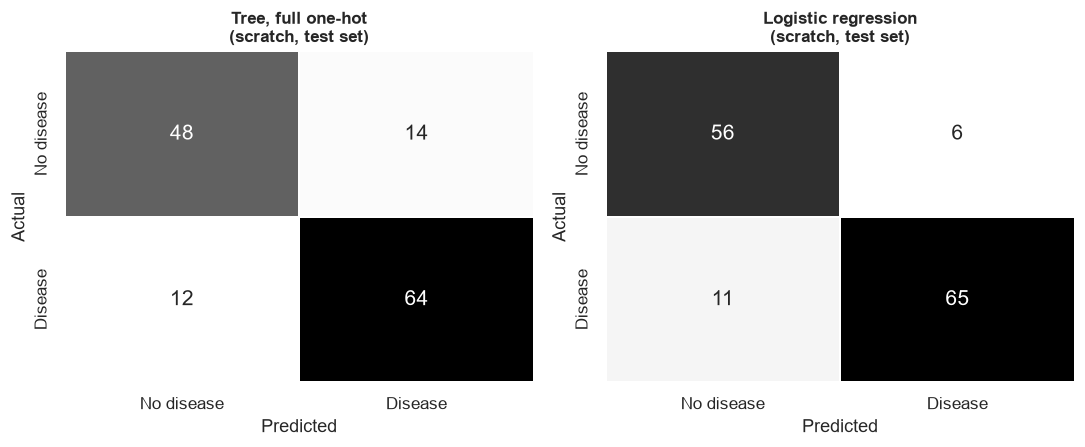

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, label in zip(axes, [FINAL_TREE, FINAL_LR]):
    cm = confusion_matrix(y_test, test_pred[(label, 'scratch')])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greys', cbar=False, ax=ax, linewidths=1, annot_kws={'size': 14},
                xticklabels=['No disease', 'Disease'], yticklabels=['No disease', 'Disease'])
    ax.set_title(label + '\n(scratch, test set)', fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); save_fig('fig06_confusion_matrices'); plt.show()

**Reading the test results.** Logistic regression (accuracy 0.877 for the scratch model, 0.884 for scikit-learn) is ahead of the tree (0.812). The two trees make identical predictions. The two logistic regressions differ on 3 of the 138 patients (agreement 0.978): the scratch model has the higher precision (0.915 against 0.905) and the lower recall (0.855 against 0.882), and their ROC-AUC values are 0.929 and 0.932. One test patient is worth 0.7 points of accuracy, so a difference of 3 patients is within noise.
The gap between logistic regression and the tree is 6.5 points on this test set but only 1.0 point in cross-validation. Each test accuracy is within about one standard error (about 3 points on 138 patients) of its cross-validation mean (logistic regression 0.877 against 0.853; tree 0.812 against 0.842), so this particular test set is somewhat more favourable to logistic regression than the average fold. The cross-validation figure is the more trustworthy estimate of the difference; the test set only confirms the direction.

## 7. Looking inside the models

### 7.1 The tuned decision tree (Figure 7)

Each box shows the number of training patients that reach it, as *(no disease / disease)*. Grey boxes are questions; coloured boxes are leaves, in the colour of the predicted class (blue = no disease, orange = disease). The branch for "condition true" (`x ≤ threshold`; for 0/1 columns, "No") goes up. This tree is drawn from left to right (the root is on the left) so that its 15 leaves stay readable.

Final tree: depth 4, 15 leaves


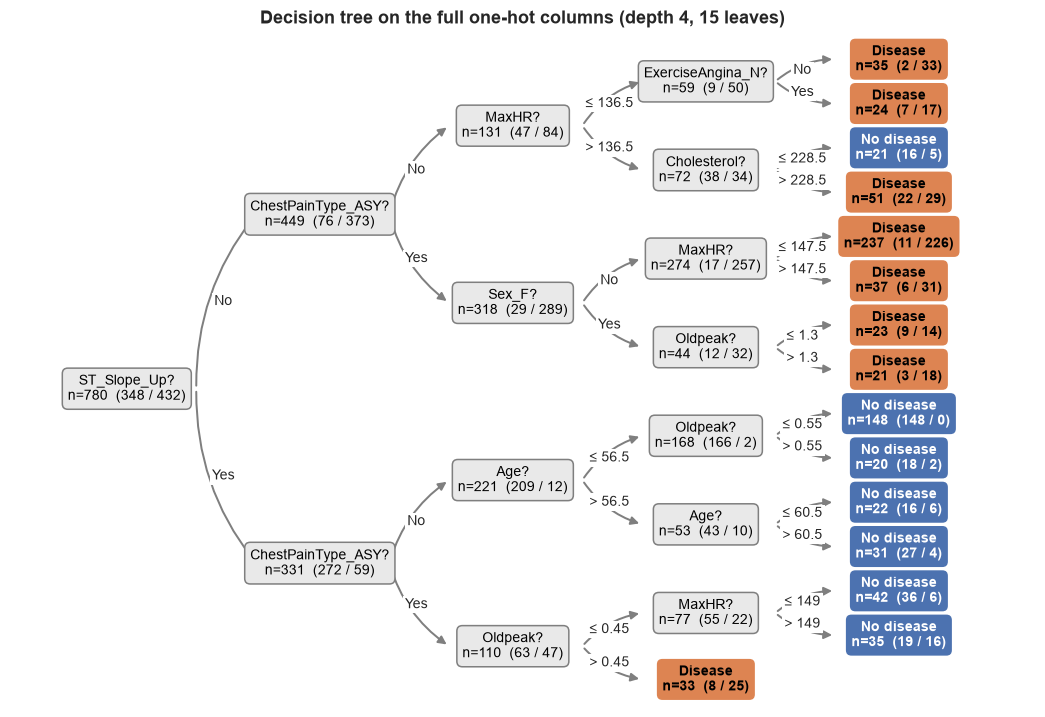

In [22]:
def draw_tree(tree, X, y, feat_names, title, fname, horizontal=False):
    """Node-link diagram of a DecisionTreeScratch. The branch for 'condition true' (x <= threshold) goes left
    (or up). horizontal=False: root at the top. horizontal=True: root on the left, better for trees with many leaves."""
    pos, counter = {}, [0]
    def layout(node, depth):                      # pos = (position along the spread axis, depth)
        if node.value is not None:
            pos[id(node)] = (counter[0], depth); counter[0] += 1
        else:
            layout(node.left, depth + 1); layout(node.right, depth + 1)
            pos[id(node)] = ((pos[id(node.left)][0] + pos[id(node.right)][0]) / 2, depth)
    layout(tree.root, 0)
    n_leaves, depth = tree.get_n_leaves(), tree.get_depth()
    def xy(node):
        s, d = pos[id(node)]
        return (d, -s) if horizontal else (s, -d)
    if horizontal:
        fig, ax = plt.subplots(figsize=(2.4 * (depth + 1), 0.45 * n_leaves + 1.2))
        ax.set_xlim(-0.6, depth + 0.7); ax.set_ylim(-n_leaves + 0.4, 0.6)
    else:
        fig, ax = plt.subplots(figsize=(max(6, 1.55 * n_leaves), 2.5 * (depth + 1)))
        ax.set_xlim(-0.8, n_leaves - 0.2); ax.set_ylim(-depth - 0.6, 0.6)
    ax.axis('off')
    def counts(yy): return f'n={len(yy)}  ({(yy == 0).sum()} / {(yy == 1).sum()})'
    def draw(node, Xn, yn):
        x, yv = xy(node)
        if node.value is not None:
            fc, tc = (C_YES, 'black') if node.value == 1 else (C_NO, 'white')
            ax.text(x, yv, ('Disease' if node.value == 1 else 'No disease') + '\n' + counts(yn), ha='center', va='center',
                    fontsize=9, color=tc, fontweight='bold', zorder=3, bbox=dict(boxstyle='round,pad=0.4', fc=fc, ec='none'))
            return
        j, th = node.feature_index, node.threshold
        binary = np.isin(np.unique(X[:, j]), [0, 1]).all()
        ax.text(x, yv, f'{feat_names[j]}?\n' + counts(yn), ha='center', va='center', fontsize=9, color='black', zorder=3,
                bbox=dict(boxstyle='round,pad=0.4', fc='#E9E9E9', ec='#7F7F7F'))
        mask = Xn[:, j] <= th
        lab_l, lab_r = ('No', 'Yes') if binary else (f'\u2264 {th:g}', f'> {th:g}')
        for child, lab, rad, Xc, yc in [(node.left, lab_l, 0.18, Xn[mask], yn[mask]),
                                       (node.right, lab_r, -0.18, Xn[~mask], yn[~mask])]:
            cx, cy = xy(child)
            start, end = ((x + 0.36, yv), (cx - 0.33, cy)) if horizontal else ((x, yv - 0.2), (cx, cy + 0.2))
            ax.annotate('', xy=end, xytext=start, zorder=1,
                        arrowprops=dict(arrowstyle='-|>', color='#7F7F7F', lw=1.3, connectionstyle=f'arc3,rad={-rad if horizontal else rad}'))
            ax.text((x + cx) / 2, (yv + cy) / 2 + (0 if horizontal else 0.03), lab, ha='center', va='center', fontsize=9, zorder=2,
                    bbox=dict(fc='white', ec='none', pad=1.5))
            draw(child, Xc, yc)
    draw(tree.root, X, y)
    ax.set_title(title, fontsize=12, fontweight='bold')
    plt.savefig(f'figures/{fname}.png', bbox_inches='tight', dpi=150); plt.show()

Xpool_tree, _ = to_arrays(pool_imp, pool_imp, TREE_COLS)
final_tree = fitted[(FINAL_TREE, 'scratch')]
print(f'Final tree: depth {final_tree.get_depth()}, {final_tree.get_n_leaves()} leaves')
draw_tree(final_tree, Xpool_tree, y_pool, TREE_COLS,
          f'Decision tree on the full one-hot columns (depth {final_tree.get_depth()}, {final_tree.get_n_leaves()} leaves)',
          'fig07_tree_diagram', horizontal=True)

### 7.2 Which features does the tree use? (Figure 8)
Importance = total Gini decrease contributed by a feature, normalised to sum to 1.

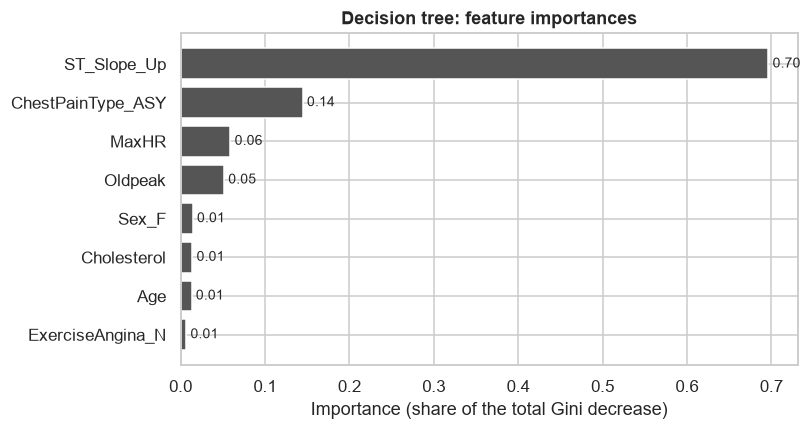

In [23]:
imp = pd.Series(final_tree.feature_importances_, index=TREE_COLS)
imp = imp[imp > 0].sort_values()
fig, ax = plt.subplots(figsize=(7.5, max(3, 0.38 * len(imp) + 1)))
ax.barh(imp.index, imp.values, color='#555555', edgecolor='white')
for yy, v in enumerate(imp.values):
    ax.text(v + 0.005, yy, f'{v:.2f}', va='center', fontsize=9)
ax.set_xlabel('Importance (share of the total Gini decrease)'); ax.set_title('Decision tree: feature importances', fontweight='bold')
plt.tight_layout(); save_fig('fig08_tree_importances'); plt.show()

### 7.3 Logistic regression weights (Figure 9)
Weights are on standardised inputs, so their sizes are comparable. Orange = the feature **raises** the predicted risk of disease, blue = it **lowers** it. Each 0/1 column is measured against its left-out reference level (female, asymptomatic chest pain, LVH on the ECG, no exercise angina, down-sloping ST).

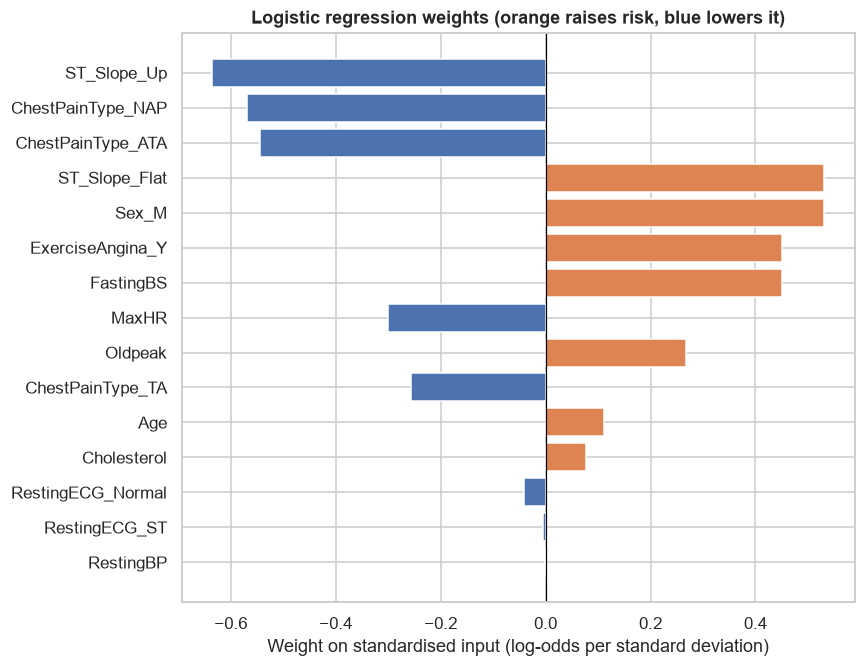

Largest weights: {'ST_Slope_Up': -0.64, 'ChestPainType_NAP': -0.57, 'ChestPainType_ATA': -0.54, 'ST_Slope_Flat': 0.53, 'Sex_M': 0.53, 'ExerciseAngina_Y': 0.45}


In [24]:
final_lr = fitted[(FINAL_LR, 'scratch')]
w = pd.Series(final_lr.weights, index=LR_COLS)
w = w.reindex(w.abs().sort_values().index)
fig, ax = plt.subplots(figsize=(8, 6.2))
ax.barh(w.index, w.values, color=[C_YES if v > 0 else C_NO for v in w.values], edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Weight on standardised input (log-odds per standard deviation)')
ax.set_title('Logistic regression weights (orange raises risk, blue lowers it)', fontweight='bold')
plt.tight_layout(); save_fig('fig09_lr_coefficients'); plt.show()
print('Largest weights:', w.reindex(w.abs().sort_values(ascending=False).index).head(6).round(2).to_dict())

### 7.4 What the encoding does to the tree (Figure 10)
The same tree algorithm, with the same tuning grid and the same folds, but given the `drop_first` columns instead of the full one-hot columns. With `drop_first`, the column `ChestPainType_ASY` (asymptomatic chest pain, the chest-pain level most associated with disease) no longer exists: it is the all-zero reference level. To isolate those patients the tree would need three questions ("not ATA, not NAP, not TA") instead of one.

Tree on the drop_first columns: depth 3, 8 leaves (selected by cross-validation: max_depth = 3, min_samples_leaf = 1)


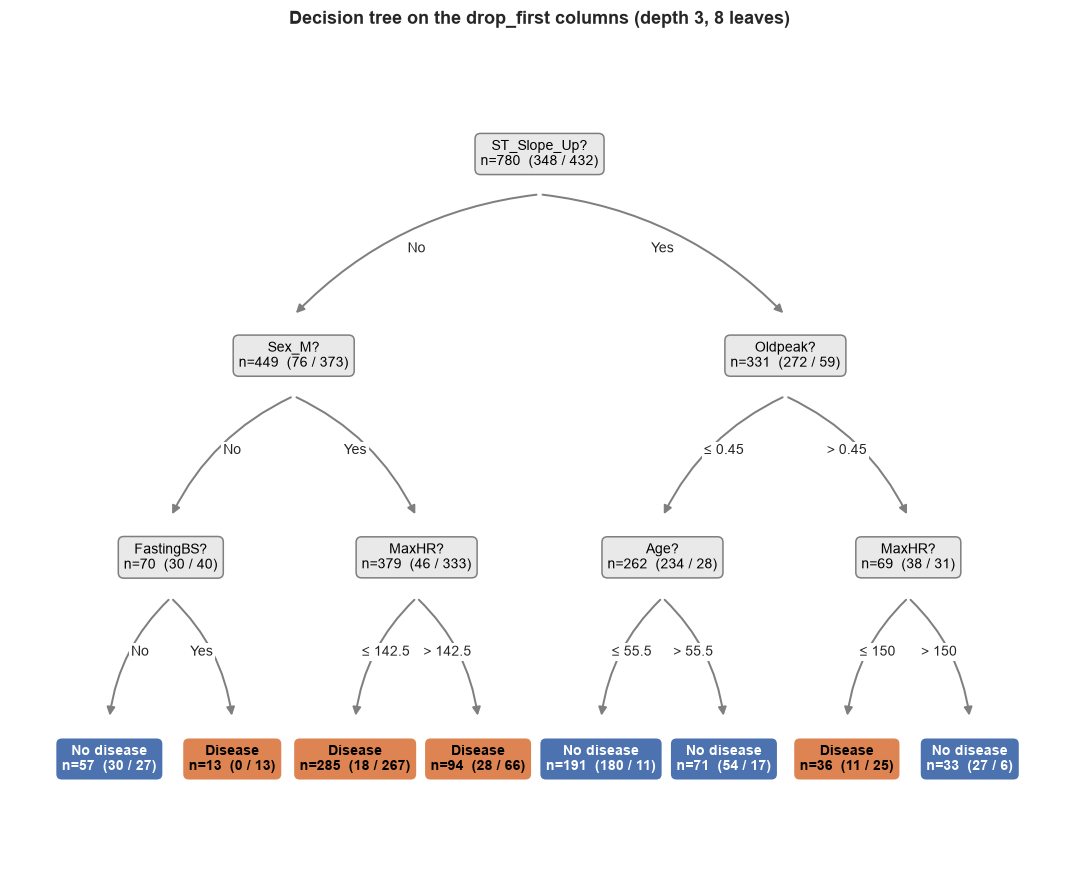

In [25]:
Xpool_drop, _ = to_arrays(pool_imp, pool_imp, DROP_TREE_COLS)
drop_tree = DecisionTreeScratch(max_depth=int(best_drop['max_depth']), min_samples_leaf=int(best_drop['min_samples_leaf'])).fit(Xpool_drop, y_pool)
print(f'Tree on the drop_first columns: depth {drop_tree.get_depth()}, {drop_tree.get_n_leaves()} leaves '
      f"(selected by cross-validation: max_depth = {int(best_drop['max_depth'])}, min_samples_leaf = {int(best_drop['min_samples_leaf'])})")
draw_tree(drop_tree, Xpool_drop, y_pool, DROP_TREE_COLS,
          f'Decision tree on the drop_first columns (depth {drop_tree.get_depth()}, {drop_tree.get_n_leaves()} leaves)',
          'fig10_drop_first_tree')

**What this shows.** The encoding costs the tree only a little: cross-validation selects a tree with 3 levels and 8 leaves on the `drop_first` columns (mean accuracy 0.833), against 0.842 for the full one-hot tree, and the full one-hot tree is better in only 3 of 5 folds (mean +0.9 points). The `drop_first` tree never uses the asymptomatic-chest-pain information directly; it builds on `ST_Slope_Up`, `Sex_M`, `Oldpeak`, `MaxHR`, `FastingBS` and `Age` instead.
An important point about tuning: if the depth were chosen on a single small validation split, depths 1 and 2 could tie and the first tie would give a tree with **one split** (the same `ST_Slope_Up` split under both encodings). That result would depend on the tie-break and on the split, not on the encoding alone. Cross-validation, which averages over five validation sets, and `min_samples_leaf` in the grid avoid this.
**Our choice.** The tree gets the full one-hot columns (every level has its own column, which suits a split search) and the logistic regression gets the `drop_first` columns (unique, interpretable weights). Both views contain exactly the same information, so the comparison is still fair.

### 7.5 Trading precision for recall (Figure 11)
The default rule "predict disease if $\hat p\ge 0.5$" treats both mistakes alike. A missed patient is worse than a false alarm, so we look at what happens when the threshold is lowered. To avoid using the test set, the curves are computed from the **out-of-fold** predictions of the final logistic regression: every pool patient is predicted by a model that did not see them.

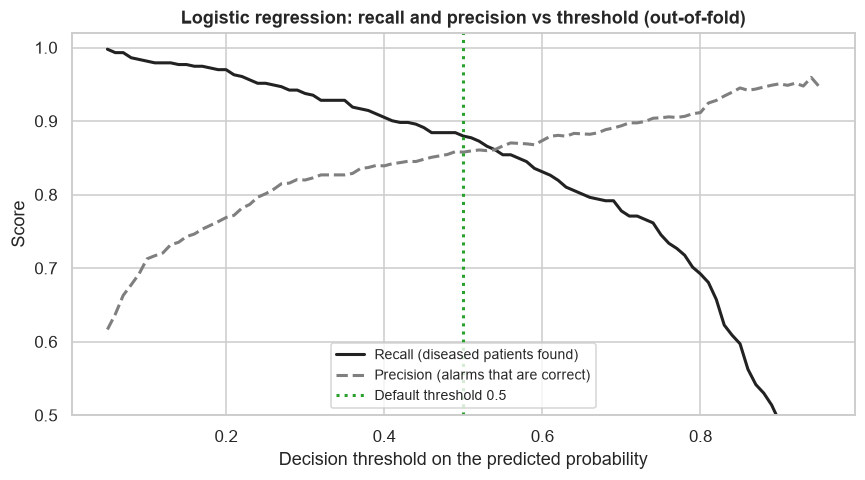

,recall,precision,missed patients (FN),false alarms (FP)
threshold,,,,
0.5,0.880,0.858,52,63
0.4,0.905,0.839,41,75
0.3,0.938,0.820,27,89
0.2,0.970,0.769,13,126


In [26]:
oof_proba = np.zeros(len(y_pool))
Xs = [to_arrays(f['tr'], f['va'], LR_COLS, scale=True) for f in folds]
for (Xtr, Xva), f, (_, va) in zip(Xs, folds, skf.split(X_pool, y_pool)):
    oof_proba[va] = LogisticRegressionScratch(lr=best_alpha, n_iterations=N_ITER).fit(Xtr, f['y_tr']).predict_proba(Xva)

thr = np.linspace(0.05, 0.95, 91)
rec = np.array([recall_score(y_pool, (oof_proba >= t).astype(int)) for t in thr])
prec = np.array([precision_score(y_pool, (oof_proba >= t).astype(int), zero_division=0) for t in thr])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thr, rec, color='#222222', linewidth=2, label='Recall (diseased patients found)')
ax.plot(thr, prec, color='#7F7F7F', linewidth=2, linestyle='--', label='Precision (alarms that are correct)')
ax.axvline(0.5, color='#2ca02c', linestyle=':', linewidth=2, label='Default threshold 0.5')
ax.set_xlabel('Decision threshold on the predicted probability'); ax.set_ylabel('Score'); ax.set_ylim(0.5, 1.02)
ax.set_title('Logistic regression: recall and precision vs threshold (out-of-fold)', fontweight='bold')
ax.legend(loc='lower center', fontsize=9)
plt.tight_layout(); save_fig('fig11_lr_recall_threshold'); plt.show()

rows = []
for t in (0.5, 0.4, 0.3, 0.2):
    p = (oof_proba >= t).astype(int)
    cm = confusion_matrix(y_pool, p)
    rows.append({'threshold': t, 'recall': recall_score(y_pool, p), 'precision': precision_score(y_pool, p),
                 'missed patients (FN)': int(cm[1, 0]), 'false alarms (FP)': int(cm[0, 1])})
display(pd.DataFrame(rows).round(3).set_index('threshold'))

**Reading Figure 11.** Lowering the threshold from 0.5 to 0.3 raises recall from 0.880 to 0.938 and reduces the number of missed patients from 52 to 27 (out of 432 diseased patients in the pool), at the price of more false alarms (63 to 89 out of 348 healthy patients). At 0.2 recall is 0.970 with 13 missed patients, but 126 false alarms. We do not pick a threshold here, because that depends on how a missed patient is weighed against a false alarm; the figure only shows the trade-off.

## 8. Computational cost

Median fit time on the 780 pool patients (5 runs; machine dependent).

In [27]:
def median_time(fit, repeats=5):
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fit(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts)) * 1000

Xt, _ = to_arrays(pool_imp, pool_imp, TREE_COLS)
Xl, _ = to_arrays(pool_imp, pool_imp, LR_COLS, scale=True)
td, tl = int(best_tree['max_depth']), int(best_tree['min_samples_leaf'])
timing = pd.DataFrame({
    'Scratch (ms)': [median_time(lambda: make_tree('scratch', td, tl).fit(Xt, y_pool)),
                     median_time(lambda: make_lr('scratch', best_alpha).fit(Xl, y_pool))],
    'scikit-learn (ms)': [median_time(lambda: make_tree('sklearn', td, tl).fit(Xt, y_pool)),
                          median_time(lambda: make_lr('sklearn', best_alpha).fit(Xl, y_pool))]},
    index=['Decision tree', 'Logistic regression'])
timing['Slower by'] = (timing['Scratch (ms)'] / timing['scikit-learn (ms)']).round(1).astype(str) + 'x'
display(timing.round(1))

,Scratch (ms),scikit-learn (ms),Slower by
Decision tree,84.3,2.2,38.6x
Logistic regression,187.0,8.5,22.1x


**Reading the timings.** In this run our tree is roughly 35 to 50 times slower than scikit-learn's and our logistic regression roughly 20 to 30 times slower (the exact values vary from run to run). For the tree, our search recomputes the impurity of both children from scratch for every threshold, which costs about $O(d\,n^2)$ per node, whereas scikit-learn sorts each feature once and sweeps with running class counts, about $O(d\,n\log n)$. For logistic regression, we run 2000 plain NumPy gradient steps, while scikit-learn's L-BFGS uses curvature information and stops as soon as its tolerance is met. This is fine for 780 patients but would not scale to large data.

## 9. Discussion and conclusion

### 9.1 What we found
1. **Both scratch implementations are correct.** The gradient passes a finite-difference check (error about $5\times10^{-12}$), the scratch tree gives the same predictions as scikit-learn's tree in every fold and on the test set, and the scratch logistic regression agrees with scikit-learn on about 98 % of the predictions (98.7 % in cross-validation, 97.8 % on the test set), with differences that go in both directions.
2. **Logistic regression is probably slightly better, but the evidence is modest.** Cross-validated accuracy is 0.853 against 0.842 for the tree (better in 3 of 5 folds, tied in 2, mean +1.0 point), and 0.877 against 0.812 on the test set. Since each model varies by about 3 points between folds, we call logistic regression "probably slightly better" and not clearly better. A weighted sum of all features suits this data, while a tree has to approximate smooth relations (for example risk rising as the maximum heart rate falls) with steps, and can change shape with small changes in the training data (we expect this, but did not measure it).
3. **Preprocessing matters, but less than the choice of evaluation design.** Median imputation fitted inside each fold avoids leakage, and the encoding affects the tree only slightly once the tree is tuned by cross-validation.
4. **The tree is easy to read, the logistic regression is slightly more accurate.** The tree's first question is the exercise ST slope, then chest pain type (Figure 7). Both models rely mainly on `ST_Slope_Up` and the chest-pain indicators (Figures 8 and 9).
5. **Recall can be traded for precision** by lowering the threshold (Figure 11).

### 9.2 Limitations
- **Small data.** 918 patients; a test set of 138 has a standard error of about 3 points, so differences of one or two points are not meaningful. Hyperparameters were chosen on the same folds that are reported, so the cross-validation scores are slightly optimistic; the test set is the unbiased check.
- **Mixed sources.** The data merge five hospital datasets, 79 % of the patients are male, and the missing cholesterol values probably come from particular sources (the file has no column that tells us). Results may not transfer to other populations.
- **Imputation.** 172 cholesterol values (19 %) are replaced by one median. These patients are 88 % diseased against 48 % of the other patients, so the fact that a value is missing is itself informative. A "was missing" indicator column would probably raise accuracy a little, but it would mostly reflect which source hospital a patient came from and not the patient, so we did not use it.
- **Optimisation.** Gradient descent runs a fixed 2000 iterations without a convergence test; the learning rate is chosen from six values only.
- **Medical use.** About 1 in 8 diseased patients is missed at the default threshold. This is a learning project and not a diagnostic tool.

### 9.3 Possible improvements
A convergence-based stopping rule for gradient descent, a faster (sorted) split search for the tree, and an ensemble of trees to reduce the tree's variance.

## References
1. fedesoriano. *Heart Failure Prediction Dataset.* Kaggle, 2021. https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction
2. Breiman, L., Friedman, J., Olshen, R., Stone, C. *Classification and Regression Trees.* Wadsworth, 1984.
3. Hastie, T., Tibshirani, R., Friedman, J. *The Elements of Statistical Learning*, 2nd ed. Springer, 2009 (Chapters 4 and 9).
4. Pedregosa, F. et al. Scikit-learn: Machine Learning in Python. *JMLR* 12, 2825-2830, 2011.